#### Train and compare Bagging, Random Forest, Gradient Boosting, and Stacking models, tune the boosting learning rate with early stopping, and evaluate Stacking against its individual base models?

In [3]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

X, y = make_classification(n_samples=1000, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2, stratify=y, random_state=42)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
search = GridSearchCV(GradientBoostingClassifier(n_estimators=300, n_iter_no_change=5, random_state=42), {"learning_rate": [0.03, 0.1, 0.2]}, cv=5, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
gb=search.best_estimator_

models = {
    "Bagging": BaggingClassifier(n_estimators=100, random_state=42),
    "Random Forest": rf,
    "Boosting": gb,
    "Stacking": StackingClassifier(
        [("rf",rf), ("gb", gb)], final_estimator=LogisticRegression(), cv=5
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, "accuracy:", round(accuracy_score(y_test, pred), 3), "macro-F1:", round(f1_score(y_test, pred, average="macro"), 3))

print("best learning rate: ", search.best_params_["learning_rate"])
print("boosting rounds used:", gb.n_estimators_)

Bagging accuracy: 0.92 macro-F1: 0.92
Random Forest accuracy: 0.905 macro-F1: 0.905
Boosting accuracy: 0.895 macro-F1: 0.895
Stacking accuracy: 0.895 macro-F1: 0.895
best learning rate:  0.03
boosting rounds used: 134


### Implement backpropagation from scratch.

In [8]:
import numpy as np

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

lr = 0.01

sigmoid = lambda z: 1 / (1 + np.exp(-z))

W1 = np.random.randn(2, 4)
W2 = np.random.randn(4, 1)
b1 = np.zeros((1, 4))
b2 = np.zeros((1, 1))

for _ in range(1000):
    # Forward Pass
    h = sigmoid(X @ W1 + b1)
    pred = sigmoid(h @ W2 + b2)

    # Backpropagation
    d2 = (pred - y) / len(X)

    dW2, db2 = h.T @ d2, d2.sum(axis=0, keepdims=True)

    d1 = (d2 @ W2.T) * h * (1-h)

    dW1, db1 = X.T @ d1, d1.sum(axis=0, keepdims=True)

    W1 -= dW1 
    b1 -= db1 

    W2 -= dW2 
    b2 -= db2 

print((pred > 0.5).astype(int).ravel())


[0 1 1 0]


## 3. Time Series Analysis

### Decompose a series into trend, seasonality, and residuals.

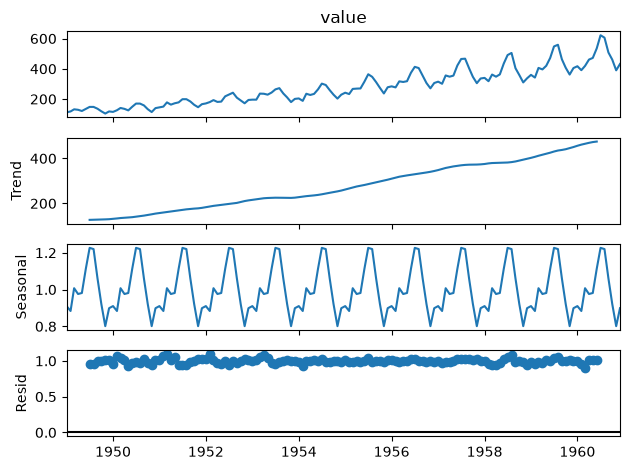

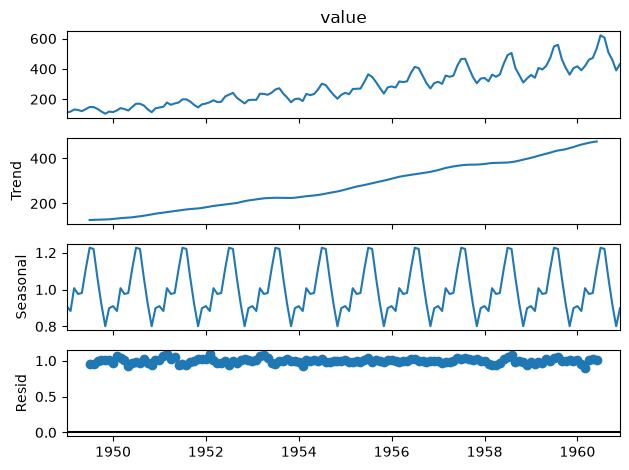

In [10]:
import pandas as pd
import matplotlib.pyplot as plt 
import statsmodels.api as sm 
from statsmodels.tsa.seasonal import seasonal_decompose

series = sm.datasets.get_rdataset("AirPassengers").data["value"]
series.index = pd.date_range("1949-01-01", periods=len(series), freq="MS")

result = seasonal_decompose(series, model="multiplicative", period=12)
result.plot()
result.plot()
plt.tight_layout()
plt.show()

#### How do you check stationarity using differencing, transformations, and decomposition?

In [13]:
# Answer
from statsmodels.tsa.stattools import adfuller

diff = series.diff(12).diff()
p = adfuller(diff.dropna())[1]

print(f"p-value={p}")

p-value=1.8565116001234439e-28


/var/folders/xj/k0m7g06133vf7zhcrt6zz78h0000gn/T/ipykernel_81122/941542038.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p = adfuller(diff.dropna())[1]


### How do you use ACF and PACF plots to choose ARIMA parameters, then fit, evaluate, and visualize an ARIMA model in `statsmodels`? 

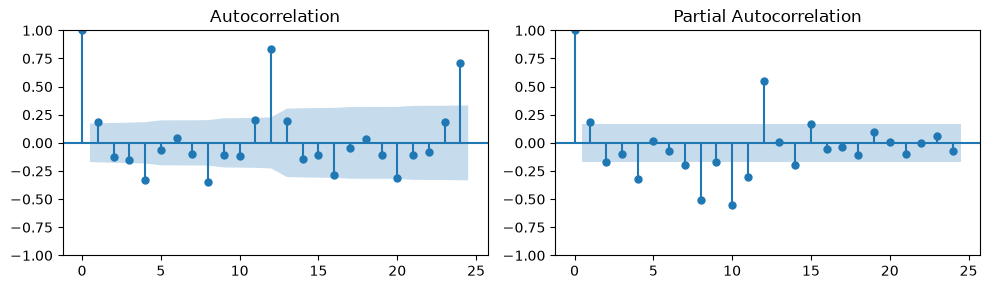

MSE: 0.03747482770123841


In [16]:
import numpy as np 
import matplotlib.pyplot as plt 
import statsmodels.api as sm 
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

dataset = sm.datasets.get_rdataset("AirPassengers").data 

series = dataset['value']
y = np.log(series)

train, test = y.iloc[:-12], y.iloc[-12:]

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
plot_acf(train.diff().dropna(), lags=24, ax=ax[0])
plot_pacf(train.diff().dropna(), lags=24, method="ywm", ax=ax[1])
plt.tight_layout()
plt.show()

model = ARIMA(train, order=(1, 1, 1))
fitted_model = model.fit()

forecast = fitted_model.forecast(steps=len(test))
mse=mean_squared_error(test, forecast)

print(f"MSE: {mse}")

### How do you implement and evaluate a SARIMA model and single, double, and Holt-Winters exponential-smoothing models with `statsmodels`, then compare their forecasts?

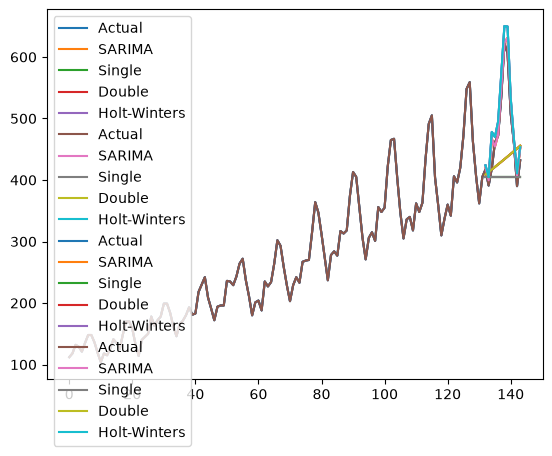

In [22]:
import numpy as np 
import matplotlib.pyplot as plt 
from statsmodels.tsa.statespace.sarimax import SARIMAX 
from statsmodels.tsa.holtwinters import (SimpleExpSmoothing, Holt, ExponentialSmoothing)
from sklearn.metrics import mean_squared_error

y = np.log(series)

train, test = y.iloc[:-12], y.iloc[-12:]

models = {
    "SARIMA": SARIMAX(train, order=(1,1,1), seasonal_order=(1, 1,1 ,12)).fit(disp=False),
    "Single": SimpleExpSmoothing(train, initialization_method="estimated").fit(),
    "Double": Holt(train, initialization_method="estimated").fit(),
    "Holt-Winters": ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated").fit(),
}

forecasts = {name: model.forecast(12) for name,model in models.items()}

for name, forecast in forecasts.items():
    rmse = np.sqrt(mean_squared_error(np.exp(test), np.exp(forecast)))

    plt.plot(series.index, series, label="Actual")
    for name, forecast in forecasts.items():
        plt.plot(test.index, np.exp(forecast),label=name)
        plt.legend()

plt.show()


### How do you build, evaluate, and visualize a Prophet forecast, then extend it with country holidays, special events, and an additional regressor?

08:02:22 - cmdstanpy - INFO - Chain [1] start processing
08:02:22 - cmdstanpy - INFO - Chain [1] done processing


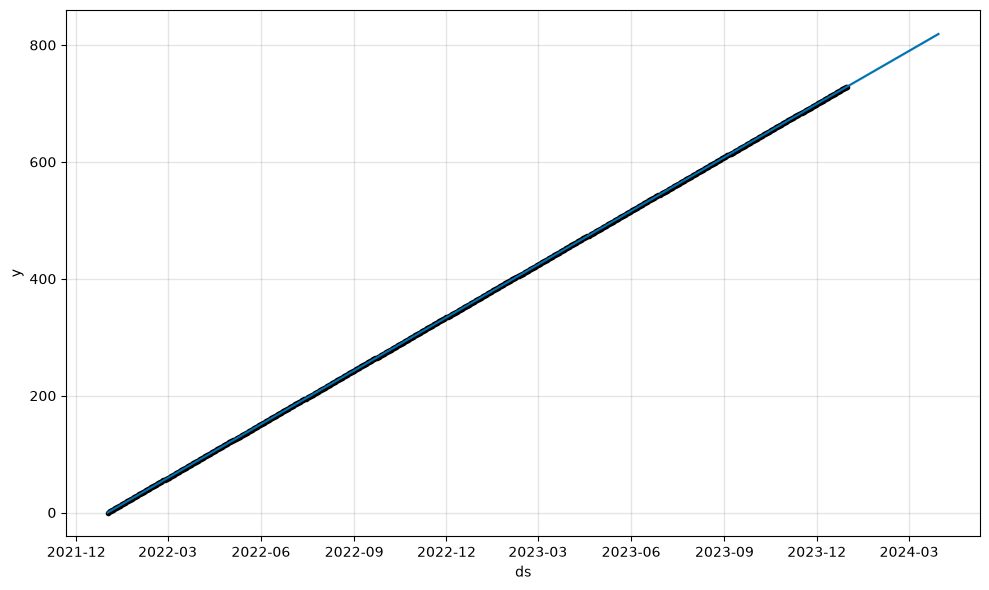

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet 

df = pd.DataFrame({
    "ds": pd.date_range("2022-01-01", periods=730),
    "y": range(730)
})

model = Prophet()
model.fit(df)

future = model.make_future_dataframe(periods=90)
forecast = model.predict(future)

model.plot(forecast)
plt.show()

## 4. Recurrent Neural Networks (RNNs)

### 1. Build a simple RNN from scratch with NumPy.

In [24]:
import numpy as np 

wx, wh, wy = 0.1, 0.1, 0.1 
lr = 0.1

X = [1.0, 2.0, 3.0]
Y = [2.0, 3.0, 4.0]

# forward pass
H = [0.0]
Y_pred = []

for x in X:
    h = np.tanh(wx * x + wh * H[-1])
    H.append(h)
    Y_pred.append(wy * h)

# Backward pass 

dwx = dwh = dwy = 0.0
dh_next = 0.0

for t in reversed(range(len(X))):
    dy = Y_pred[t] - Y[t]
    dwy += dy * H[t+1]

    dh = wy * dy + dh_next
    dh_raw = (1-H[t+1]**2) * dh 

    dwx += dh_raw * X[t]
    dwh += dh_raw * H[t]
    dh_next = wh * dh_raw 

wx -= lr * dwx 
wh -= lr * dwh 
wy -= lr * dwy 

print("prediction", Y_pred)



prediction [np.float64(0.009966799462495582), np.float64(0.020693472112300316), np.float64(0.031013382783067464)]


### 2. Implement LSTM and GRU networks with TensorFlow/Keras.

In [25]:
import tensorflow as tf 

X = tf.constant([[[1.0], [2.0], [3.0]]])
Y = tf.constant([[[2.0], [3.0], [4.0]]])

for layer in [tf.keras.layers.LSTM, tf.keras.layers.GRU]:
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(3, 1)),
        layer(1, return_sequences=True),
        tf.keras.layers.Dense(1)
    ])

    model.compile(optimizer="adam", loss="mse")
    model.fit(X, Y, epochs=200, verbose=0)

    print(layer.__name__, model.predict(X, verbose=0).ravel())

LSTM [0.18445536 0.18388505 0.19028112]
GRU [0.5291796  0.6289991  0.63561195]


## 5. Convolutional Neural Networks (CNNs)

### 1. Implement a simple CNN from scratch.

In [26]:
import tensorflow as tf
from tensorflow.keras import layers 

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test = x_test.reshape(-1, 28, 28, 1) / 255.0


model = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(8, 3, activation="relu"),
    layers.MaxPool2D(2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.fit(x_train, y_train, epochs=3)

loss, acc = model.evaluate(x_test, y_test)
print("acc", acc)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9080 - loss: 0.3288
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9613 - loss: 0.1364
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9729 - loss: 0.0956
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9714 - loss: 0.0905
acc 0.9714000225067139


OpenCV Practices

- Use OpenCV to read and display images.
- Build an image-preprocessing workflow with resizing, cropping, flipping, normalization, blurring, thresholding, morphological operations, and edge detection.
- Apply data augmentation with rotations, translations, scaling, perspective transforms, brightness and contrast changes, and synthetic noise.
- Combine OpenCV transformations with TensorFlow/Keras augmentation.
- Use OpenCV to add text, blend transparent image layers, match shapes and templates, and calculate image gradients.

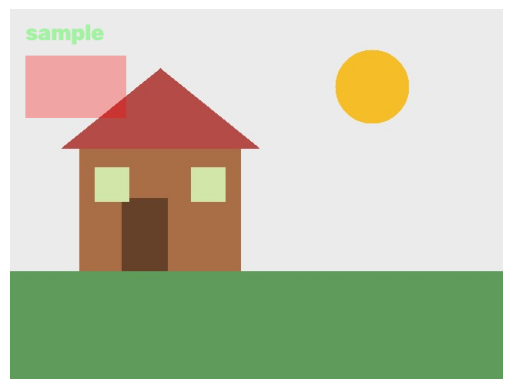

In [28]:
import cv2 
import numpy as np 
import matplotlib.pyplot as plt 

img = cv2.imread("img.jpg")

h, w = img.shape[:2]

# Preprocessing
resized = cv2.resize(img, (256, 256))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
normalized = resized.astype(np.float32) / 255.0

# Geometric augmentation
flipped = cv2.flip(img, 1)
M = cv2.getRotationMatrix2D((w/2, h/2), 15, 1.0)
rotated = cv2.warpAffine(img, M, (w, h))

# Color Augmentation
adjusted = cv2.convertScaleAbs(img, alpha=1.2, beta=20)

overlay = img.copy()
cv2.putText(overlay, "sample", (20, 40), cv2.FONT_HERSHEY_COMPLEX, 1, (0, 255, 0), 2)
cv2.rectangle(overlay, (20, 60), (150, 140), (0, 0, 255), -1)
marked = cv2.addWeighted(overlay, 0.3, img, 0.7, 0)

plt.imshow(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## 6. Generative Models

### 1. Implement a Variational Autoencoder with TensorFlow/Keras.

In [3]:
import tensorflow as tf
from tensorflow.keras import layers

encoder = tf.keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(2)
])

decoder = tf.keras.Sequential([
    layers.Input(shape=(1, )),
    layers.Dense(1)
])

optimizer = tf.keras.optimizers.Adam(0.01)

X = tf.constant([[0.0], [0.2], [0.8], [1.0]])

for step in range(1000):
    with tf.GradientTape() as tape:
        mean, log_var = tf.split(encoder(X), 2, axis=1)

        noise = tf.random.normal(tf.shape(mean))
        z = mean + tf.exp(0.5 * log_var) * noise 

        reconstruction = decoder(z)
        reconstruction_loss = tf.reduce_mean(tf.square(X - reconstruction))

        kl_loss = -0.5 * tf.reduce_mean(
            1 + log_var - mean**2 - tf.exp(log_var)
        )

        loss = reconstruction_loss + kl_loss

        weights = encoder.trainable_variables + decoder.trainable_variables
        gradients = tape.gradient(loss, weights)
        optimizer.apply_gradients(zip(gradients, weights))


print(decoder(tf.random.normal((5, 1))).numpy())
        


[[0.43456656]
 [0.45802408]
 [0.49163765]
 [0.47041678]
 [0.47990394]]




###  Build a simple GAN from scratch with TensorFlow/Keras.

In [5]:
import tensorflow as tf 
from tensorflow.keras import layers 

G = tf.keras.Sequential([
    layers.Input(shape=(1, )),
    layers.Dense(1)
])

D = tf.keras.Sequential([
    layers.Input(shape=(1, )),
    layers.Dense(1, activation="sigmoid")
])

loss = tf.losses.BinaryCrossentropy()
g_opt = tf.optimizers.Adam(0.1)
d_opt = tf.optimizers.Adam(0.1)

real = tf.ones((16, 1))
ones = tf.ones((16, 1))
zeros = tf.zeros((16, 1))

for step in range(1000):
    noise = tf.random.normal((16, 1))

    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = G(noise)

        real_pred = D(real)
        fake_pred = D(fake)

        g_loss = loss(ones, fake_pred)

        d_loss = loss(ones, real_pred) + loss(zeros, fake_pred)

        g_grads = gt.gradient(g_loss, G.trainable_variables)
        d_grads = dt.gradient(d_loss, D.trainable_variables)

        g_opt.apply_gradients(zip(g_grads, G.trainable_variables))
        d_opt.apply_gradients(zip(d_grads, D.trainable_variables))

print("Generated numbers:")
print(G(tf.random.normal((5, 1))).numpy())

Generated numbers:
[[-0.81677353]
 [-0.98719925]
 [-0.99895227]
 [-0.8601051 ]
 [-1.0540006 ]]


## 7. Attention and Transformer Models

### Build a simple Transformer from scratch.

In [7]:
import tensorflow as tf 
from tensorflow.keras import layers 

class TranformerBlock(layers.Layer):
    def __init__(self, d_model, num_heads):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads 
        )

        self.feed_forward = tf.keras.Sequential([
            layers.Dense(d_model, activation="relu"),
            layers.Dense(d_model)
        ])

        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()

    def call(self, x):
        attended = self.attention(x, x)
        x = self.norm1(x + attended)

        fed = self.feed_forward(x)
        return self.norm2(x+fed) 

X = tf.random.normal((1, 3, 4))

block = TranformerBlock(d_model=4, num_heads=2)
output = block(X)

print(output.shape)
    

(1, 3, 4)


### Fine-tune BERT for text classification

Replace the example texts and labels with your dataset. Dynamic padding, mixed precision, gradient accumulation, and checkpointing help optimize training and memory use.

In [ ]:
from datasets import Dataset 
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(name)

tokens = tokenizer(
    ["Great Product", "Terrible exp"],
    padding=True,
    truncated=True
)

data = Dataset.from_dict({
    **tokens,
    "labels": [1, 0]
})

model = AutoModelForSequenceClassification.from_pretrained(
    name, num_labels=2
)

trainer = Trainer(
    model=model,
    args = TrainingArguments(
        output_dirs="bert-results",
        num_train_epochs=3,
        report_to="none"
    ),
    train_dataset=data,
)

trainer.train()

## NLP


#### Given the following text:
```
text = (
    "I can't believe how good this movie was! "
    "The actors were running everywhere. "
    "Apple opened an office in London. "
    "Cats and dogs love playing outside."
)
```

Perform these tasks:
1. Clean the text: expand contractions, lowercase, remove punctuation, correct spelling, and remove stopwords.
2. Apply Porter and Snowball stemming.
3. Apply lemmatization and display POS tags.
4. Extract named entities.
5. Build TF-IDF vectors and calculate cosine similarity between two sentences.
6. Train CBOW and Skip-gram Word2Vec models.
7. Analyze sentiment using VADER and TextBlob.
8. Discover two topics using LDA.

In [12]:
import re 
import nltk 
import spacy 
import contractions

from textblob import TextBlob
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from gensim.models import Word2Vec, LdaModel
from gensim.corpora import Dictionary

nlp = spacy.load("en_core_web_sm")

text = (
    "I can't believe how good this movie was! "
    "The actors were running everywhere. "
    "Apple opened an office in London. "
    "Cats and dogs love playing outside."
)

stop_words = set(stopwords.words("english"))

def clean(text):
    text = contractions.fix(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = str(TextBlob(text).correct())
    return [w for w in text.split() if w not in stop_words]

words = clean(text)
print("cleaned", words)

# Stemming
porter = PorterStemmer()
snowball = SnowballStemmer("english")

print("Porter:", [porter.stem(w) for w in words])
print("Snowball: ", [snowball.stem(w) for w in words])

# Lemma
doc = nlp(text)

for token in doc:
    if token.is_alpha:
        print(token.text, token.lemma_, token.pos_)

# NER 
for entity in doc.ents:
    print(entity.text, entity.label_)

# Prepare
sentences = [clean(sentence.text) for sentence in doc.sents]
documents = [" ".join(sentence) for sentence in sentences]

tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform(documents)

print("Vocab: ", tfidf.get_feature_names_out())
print("Tf-idf: ", matrix.toarray())
print("Similarity: ", cosine_similarity(matrix[0], matrix[1])[0, 0])

# Word2Vec
cbow = Word2Vec(sentences, vector_size=20, min_count=1, sg=0)
skipgram = Word2Vec(sentences, vector_size=20, min_count=1, sg=1)

print("CBOW", cbow.wv["movie"])
print("Skipgram", skipgram.wv["movie"])

# Sentiment Analysis
vader = SentimentIntensityAnalyzer()

print("VADER: ", vader.polarity_scores(text))
print("TextBlob: ", TextBlob(text).sentiment.polarity)

# topic modeling
dictionary = Dictionary(sentences)
corpus = [dictionary.doc2bow(sentence) for sentence in sentences]

lda = LdaModel(
    corpus,
    id2word=dictionary,
    num_topics=2,
    passes=10,
    random_state=42
)

print("Topics: ", lda.print_topics())


cleaned ['cannot', 'believe', 'good', 'movie', 'actors', 'running', 'everywhere', 'apple', 'opened', 'office', 'london', 'cats', 'dogs', 'love', 'playing', 'outside']
Porter: ['cannot', 'believ', 'good', 'movi', 'actor', 'run', 'everywher', 'appl', 'open', 'offic', 'london', 'cat', 'dog', 'love', 'play', 'outsid']
Snowball:  ['cannot', 'believ', 'good', 'movi', 'actor', 'run', 'everywher', 'appl', 'open', 'offic', 'london', 'cat', 'dog', 'love', 'play', 'outsid']
I I PRON
ca can AUX
believe believe VERB
how how SCONJ
good good ADJ
this this DET
movie movie NOUN
was be AUX
The the DET
actors actor NOUN
were be AUX
running run VERB
everywhere everywhere ADV
Apple Apple PROPN
opened open VERB
an an DET
office office NOUN
in in ADP
London London PROPN
Cats cat NOUN
and and CCONJ
dogs dog NOUN
love love NOUN
playing play VERB
outside outside ADV
Apple ORG
London GPE
Vocab:  ['actors' 'apple' 'believe' 'cannot' 'cats' 'dogs' 'everywhere' 'good'
 'london' 'love' 'movie' 'office' 'opened' 'out

## Big Data Practical Coding Questions

### 1. MapReduce: Word Count
**Question:** Write a mapper that emits `(word, 1)` for every word in the input, then write a reducer that adds the counts for each word. The mapper and reducer read from standard input and write tab-separated results to standard output.

In [14]:
import re 
from collections import Counter 

text = "Hello hello world" 

# Mapper 
mapped = [(word, 1) for word in re.findall(r"\w+", text.lower())]

# Reducer
counts = Counter()

for word, count in mapped:
    counts[word] += count 

print(counts)


Counter({'hello': 2, 'world': 1})


1.⁠ ⁠Extract
* Read both CSV files using Spark.
* Infer schema and verify row counts.

2.⁠ ⁠Transform
* Drop columns with more than 50% missing values.
* Fill missing numerical values with median.
* Encode Sex as numeric.
* Join train.csv with gender_submission.csv on PassengerId.
* Assemble features using VectorAssembler.
* Standardize features.

3.⁠ ⁠Load
* Write the transformed dataset to disk in Parquet format.

4.⁠ ⁠ETL Pipeline
* Combine extract, transform, and load steps into one Spark pipeline/script.
* Ensure it runs end-to-end.

5.⁠ ⁠Machine Learning
* Split data into train/test.
* Train one classification model using Spark MLlib.
* Generate predictions on test data.

6.⁠ ⁠Evaluation
* Compute accuracy and F1-score.

In [ ]:
from pyspark.sql import SparkSession, functions as F 
from pyspark.ml import Pipeline 
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator


spark = SparkSession.builder.appName("practice").getOrCreate()

df = spark.read.csv("train.csv", header=True, inferSchema=True)
gender = spark.read.csv("gender_submission.csv", header=True, inferSchema=True)

df.printSchema()
gender.printSchema()

n = df.count()
print(n, gender.count())

root
 |-- PassengerId: integer (nullable = true)
 |-- Pclass: integer (nullable = true)
 |-- Sex: string (nullable = true)
 |-- Age: double (nullable = true)
 |-- Fare: double (nullable = true)
 |-- Survived: integer (nullable = true)

root
 |-- PassengerId: integer (nullable = true)
 |-- PredictedSurvival: integer (nullable = true)

20 20


In [ ]:
# Clean
for c in df.columns:
    if df.filter(F.col(C).isNull()).count() > n/2:
        df = df.drop(c)

# Encode 
df = df.withColumn("Sex", F.when(F.col("Sex") == "male", 0.0).otherwise(1.0))

# Join
df = df.join(gender, "PassengerId", "left")

cols = ["Age", "Sex"]
filled = [c + "_filled" for c in cols]

train, test = df.randomSplit([0.8, 0.2], seed=42)

pipeline = Pipeline(stages=[
    Imputer(strategy="median", inputCols=cols, outputCols=filled),
    VectorAssembler(inputCols=filled, outputCol="vector"),
    StandardScaler(inputCol="vector", outputCol="features", withMean=True),
    LogisticRegression(labelCol="Survived", maxIter=10),
])

model = pipeline.fit(train)

# Load
model.transform(df).write.mode("overwrite").parquet("output")

# Predict
prediction = model.transform(test)
predictions.select("Survived", "prediction").show()

evaluator = MulticlassClassificationEvaluator(labelCol="Survived")

for metric in ["accuracy", "f1"]:
    print(metric, evaluator.evaluate(predictions, {evaluator.metricName: metric}))



In [ ]:
spark.stop()

### 2. Spark SQL: Filter and Group

**Question:** Using the same passenger DataFrame, display passengers older than 30 and calculate passenger count and average age for each sex.

In [ ]:
df.createOrReplaceTempView("passengers")

spark.sql("""
    SELECT Age, Sex
    FROM passengers
    WHERE Age > 30
    ORDER BY Age DESC
""").show()

### 3. Spark RDD: Filter, Map, and Reduce

**Question:** Extract error logs and count messages for each log level.

In [ ]:
logs = ["err crash", "info started", "err timeout"]

rdd = spark.sparkContext.parellelize(logs)

print(rdd.filter(lambda x: x.startswith("err")).collect())

counts = (
    rdd.map(lambda x: (x.split()[0], 1)).reduceByKey(lambda a, b: a + b)
)
print(counts.collect())

spark.stop()

## 10. Model Deployment

### 1. Serve a Saved Model Using Flask

**Question:** Load a saved model and expose a prediction API.

In [7]:
# app.py
from flask import Flask, request, jsonify
import joblib 

app = Flask(__name__)

model = joblib.load("iris_model.joblib")

@app.post("/predict")
def predict():
    features = request.json["features"]
    prediction = model.predict([features])[0]
    return jsonify({"prediction": str(prediction)})

app.run(host="0.0.0.0", port=50001)

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:50001
 * Running on http://192.168.1.33:50001
Press CTRL+C to quit


In [ ]:
# docker-compose.yml
services:
    api:
        build:
        ports:
            - "5000:5000"

### Deploy with AWS SageMaker

SageMaker hosts the model at a real-time endpoint. You need an AWS account, credentials, and a SageMaker execution role. The SageMaker scikit-learn containers support deploying scikit-learn models trained outside SageMaker.

In [ ]:
# aws_code/inference.py
import json
import os
import joblib

def model_fn(model_dir):
    saved = joblib.load(os.path.join(model_dir, "iris_model.joblib"))
    return saved 

def input_fn(request_body, content_type):
    return json.loads(request)

def predict_fn(data, saved):
    prediction = saved["model"].predict([data["features"]])[0]
    return {"class": str(saved["target_names"][prediction])}

def output_fn(prediction, accept):
    return json.dumps(prediction)

In [ ]:
import tarfiele
import sagemaker
from sagemaker.sklearn.model import SkLearnModel

session = sagemaker.Session()
role = sagemaker.get_execution_role()

# inside model.tar.gz
with tarfile.open("model.tar.gz", "w:gz") as archive:
    archive.add("iris_model.joblib")

model_data = session.upload_data(
    path="model.tar.gz",
    key_prefix="iris/model"
)

model = SKLearnModel(
    model_data=model_data,
    role=role,
    entry_point="inference.py",
    source_dir="aws_code",
    framework_version="1.4-2",
    py_version="py3"
)

predictor = model.deploy(
    initial_instance_count=1,
    instance_type="ml.m5.large",
)

# 11. MLOps

## Integrated MLflow + DVC Iris workflow

**DVC versions the dataset and pipeline outputs. MLflow records each training run’s parameters, metrics, and model.** Running training through `dvc repro` connects the two: when inputs or parameters change, DVC reruns training and MLflow records the new run.

git init

dvc init
dvc add data/iris.csv

In [ ]:
 # params.yaml
n_estimators: 100

In [ ]:
import pandas 
import json, yaml, joblib 
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

data = pd.read_csv("data/iris.csv")

X_train, X_test, y_train, y_test = train_test_split(
    data.drop(columns="target"), data["target"],
    test_size=0.2, random_state=42
)

mlflow.set_experiment("iris")

with mlflow.start_run():
    model = RandomForestClassifier(random_state=42)
    model.fit(X_train, y_train) 
    acc = model.score(X_test, y_test)

    mlflow.log_params(params)
    mlflow.log_metric("accuracy", acc)
    mlflow.sklearn.log_model(model, name="model")

    joblib.dump(model, )

# dvc.yaml
stages:
    train:
        cmd: python train.py
        deps:
            - train.py
            - data/iris.csv

        params:
            - n_estimators
        outs:
            - model.pkl
        metrics:
            - metrics.json

# Run
dvc repro

# 12. ML CI/CD 

This example uses a tiny Flask prediction endpoint. It counts predictions with Prometheus, which Grafana can display. The prediction is a placeholder for a real model.

#### Initialize Git
```bash
mkdir iris-api
cd iris-api
git init
```

#### Create requirement.txt
```txt
Flask
prometheus-client
pytest
```

In [ ]:
# app.py
from flask import Flask, Response, jsonify
from prometheus_client import Counter, generate_latest

app = Flask(__name__)
PREDICTIONS = Counter("predictions_total", "Number of predictions")

@app.get("/predict")
def predict():
    PREDICTIONS.inc()
    return jsonify({"class": "setosa"})

@app.get("/metrics")
def metrics():
    return Response(generate_latest(), mimetype="text/plain")

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)

#### Create Dockerfile:
```dockerfile
FROM python:3.12-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install -r requirements.txt
COPY app.py
CMD ["python", "app.py"]
```

In [ ]:
# test/test_app.py
from app import app

def test_predict():
    response = app.test_client().get("/predict")

    assert response.status_code == 200
    assert response.json == {"class": "setosa"}

#### Create prometheus.yml

```yaml
global:
    scarpe_interval: 5s

scrape_configs:
    - job_name: iris-api
    static_configs:
        - targets: ["api:5000"]
```

#### Create docker-compose.yaml
```yaml
services:
    api:
        build:
        ports:
            - "5000:5000"

    promotheus:
        image: prom/prometheus
        ports:
            - "9090:9090"
        volumes:
            - ./promotheus.yml:/etc/prometheus/prometheus.yml
        depends_on:
            - api

    grafana:
        image: grafana/grafana-oss
        ports:
            - "3000:3000"
        depends_on:
            - "prometheus"
```

#### Start the service
```bash
docker compose up --build
```

#### Create .github/workflows/ci.yml:

```yaml
name: CI

on: [push, pull_request]

jobs:
    test:
        runs-on: ubuntu-latest
        steps:
            - uses: actions/checkout@v6
            - uses: actions/setup-python@v5
            with:
                python-version: "3.12"
            - run: pip install -r requirements.txt
            - run: pytest -q
```

#### Commit
```bash
git add .
git commit -m "Add minimal ML API, monitoring, and CI"
```

#### Push
```bash
git remote add origin #githubrepolink
git branch -M main
git push -u origin main
```

# Machine Task

**You write ordinary Python functions. The LLM chooses which functions to call, with what arguments, and what to do with their results.** LangChain manages that back-and-forth.


In [ ]:
# Streamlit calls FastAPI
response = httpx.post(
    "http://localhost:8000/chat",
    json={
        "session_id": "chat-123",
        "message": user_input,
    }
    timeout=120,
)

st.write(response.json()["answer"])

In [ ]:
# Python functions
from langchain.tools import tool

@tool
def save_email_draft(to: str, subject:str, body:str) -> dict:
    return db.create_draft(to=to, subject=subject, body=body)

@tool
def schedule_email(draft_id: str, send_at: str) -> dict:
    return db.create_email_job(draft_id=draft_id, send_at=send_at)

@tool
def get_activity(date: str) -> list:
    return db.get_activity(date=date)

In [ ]:
# Connect models to tools
import os
from langchain.agents import create_agent
from langchain_groq import ChatGroq

agent = create_agent(
    model=ChatGroq(model=os.environ["GROQ_MODEL"]),
    tools = [save_email_draft, schedule_email, get_activity],
    system_prompt=(
        "Help users complete tasks. Ask when required details are missing. "
        "Use tool results to report what actually succeeded. "
        "Distinguish scheduled emails from sent emails."
    )
)

In [ ]:
# FastAPI serves and saves the messages
class ChatRequest(BaseModel):
    session_id: str
    message: str

@app.post("/chat")
async def chat(request: ChatRequest):
    history = db.load_messages(request.session_id)
    messages = history + [
        {"role": "user", "content": request.message}
    ]

    result = await agent.ainvoke(
        {"messages": messages},
        config={"recursion_limit": 20}
    )

    # Serialize and save the full conversation including tool messages
    db.replace_messages(request.session_id, result["messages"])

    return {"answer": result["messages"][-1].content}